# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933


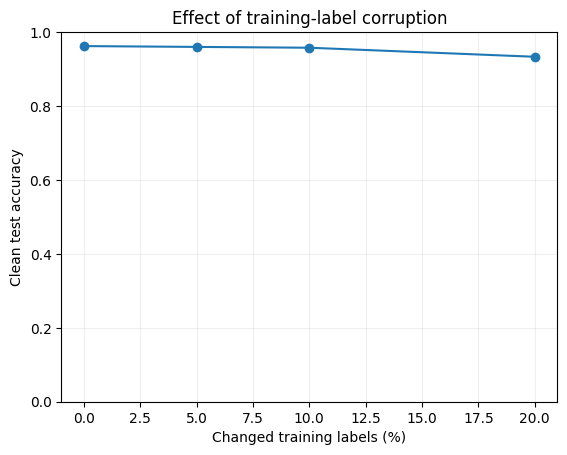

In [2]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.

In [3]:
Results table:

Corruption	Labels changed	Test accuracy
0%	  	         0             0.962
5%		         67            0.960
10%		         135           0.958
20%	             269           0.933



Exercise answers:

Why training data is a security asset:
The model learns entirely from its training labels — if those labels are compromised, the model’s behaviour is compromised at every future prediction. Unlike a software bug which can be patched, a poisoned model silently produces wrong outputs with no visible error. The damage is baked in at training time.

Comparison of results:
Accuracy degrades monotonically as corruption increases, which is the expected pattern for random label flipping. The degradation is gradual because random corruption affects all classes roughly equally and the model partially compensates by finding consistent patterns in the uncorrupted majority. A targeted attack (e.g. flipping only digit 3 → 8) would cause sharper, class-specific drops invisible in overall accuracy.

Three technical safeguards:

Cryptographic hash of the training dataset stored separately — any modification changes the hash
Label consistency audit — flag samples whose label contradicts the nearest neighbours in feature space
Version-controlled, append-only dataset storage with signed commits

Two procedural safeguards:

Dual-approval workflow — label changes require a second reviewer before merging
Periodic re-audit of a random sample of training labels by a person not involved in original labelling


    Data integrity checklist:

Control	                                   Implementation
Dataset provenance	               Record source, date, collection method
Cryptographic hash	               SHA-256 of full dataset file at creation
Label audit	                       Cross-check labels against k-NN consensus
Role-restricted writes	           Only authorised pipeline accounts can modify training data
Staged approval	                   Label changes reviewed and signed off before retraining
Anomaly review	                   Monitor per-class accuracy drops between retraining runs

SyntaxError: invalid character '—' (U+2014) (2171787897.py, line 14)